In [20]:
# Plot Banzhaf distribution by n

from kernelprob.utils.p_generator import get_p

import matplotlib.pyplot as plt
import numpy as np

beta_shap_sym = {
    "shapley" : "Shapley",
    "beta_shapley_2_2" : "Beta(2,2)",
    "beta_shapley_4_4" : "Beta(4,4)",
    "beta_shapley_8_8" : "Beta(8,8)",
    "beta_shapley_16_16" : "Beta(16,16)",
}

beta_shap_asym = {
    "shapley" : "Shapley",
    "beta_shapley_1_2" : "Beta(1,2)",
    "beta_shapley_1_4" : "Beta(1,4)",
    "beta_shapley_1_8" : "Beta(1,8)",
    "beta_shapley_1_16" : "Beta(1,16)",
}


weighted_banzhaf = {
    "banzhaf" : "Banzhaf",
    "weighted_banzhaf_0.6" : "WB(0.6)",
    "weighted_banzhaf_0.7" : "WB(0.7)",
    "weighted_banzhaf_0.8" : "WB(0.8)",
    "weighted_banzhaf_0.9" : "WB(0.9)",
}


weightings = {
    "Symmetric Beta Shapley" : beta_shap_sym,
    "Asymmetric Beta Shapley" : beta_shap_asym,
    "Weighted Banzhaf" : weighted_banzhaf,
}

linestyles = ['-', '--', '-.', ':', (5, (10, 3))]
cb_colors = [
    "#E69F00",  # Orange
    "#56B4E9",  # Sky Blue
    "#009E73",  # Bluish Green
    "#0072B2",  # Blue
    "#D55E00",  # Vermillion
    "#CC79A7",  # Reddish Purple
]

def plot_probabilistic_values(n, figsize):
    # 3 plots in a row
    fig, axs = plt.subplots(1, 3, figsize=figsize)
    for plot_idx, (weightings_name, weighting_dict) in enumerate(weightings.items()):
        ax = axs[plot_idx]
        for idx, (weighting, weighting_name) in enumerate(weighting_dict.items()):
            p = get_p(n, weighting)
            ax.plot(np.arange(n), p, label=weighting_name, linestyle=linestyles[idx], color=cb_colors[idx])
        ax.set_title(weightings_name + fr" ($n={n}$)")
        ax.set_xlabel(r"$|S|$")
        if plot_idx == 0:
            ax.set_ylabel(r"$p_{|S|}$")
        ax.set_yscale('log')
        ax.legend()

    plt.tight_layout()
    plt.savefig("images/probabilistic_values.pdf", bbox_inches='tight', dpi=300)

import scipy

def compute_bn(p, n):
    valid_sizes = np.array(list(range(n+1)))

    sum1, sum2 = 0, 0
    for ell in range(n):
        sum1 += scipy.special.binom(n-1, ell) * p[ell]**2
        if ell >= 1:
            sum2 += scipy.special.binom(n-2, ell-1) * (p[ell]-p[ell-1])**2
    an = 2*sum1 - sum2
    bn = sum2 / an
    return bn

def compute_square_prob_sum(p, n):
    total = (p[0]*n)**2 + (p[-1]*n)**2
    for size in range(1, n-1):
        total += (p[size-1] * size - p[size] * (n - size))**2 * scipy.special.binom(n, size)
    return total

def plot_bn(ns, figsize, plot_sum=False):
    # 3 plots in a row
    fig, axs = plt.subplots(1, 3, figsize=figsize)
    for plot_idx, (weightings_name, weighting_dict) in enumerate(weightings.items()):
        ax = axs[plot_idx]
        for idx, (weighting, weighting_name) in enumerate(weighting_dict.items()):
            bns = []
            for n in ns:
                p = get_p(n, weighting)
                if plot_sum:
                    bns += [compute_square_prob_sum(p, n)]
                else:
                    bns += [compute_bn(p, n)]
            ax.plot(ns, bns, label=weighting_name, linestyle=linestyles[idx], color=cb_colors[idx])
        ax.set_title(weightings_name)
        ax.set_xlabel(r"$n$")
        if plot_idx == 0:
            ax.set_ylabel(r"$b_n$" if not plot_sum else r"Prob Square Sum")
        ax.set_xscale('log')
        #ax.set_yscale('log')
        ax.legend()

    plt.tight_layout()
    try:
        plt.savefig("images/bn.pdf", bbox_inches='tight', dpi=300)
    except:
        plt.show()



In [46]:
for weighting in weightings:
    for weighting_name in weightings[weighting]:
        print(weighting_name)
        n = 10
        p = get_p(n, weighting_name)
        b = [1/np.sqrt(p[0]*p[1]),1/np.sqrt(p[0])]
        for ell in range(1, n):
            numerator = p[ell] * b[ell-1]**2
            denominator1 = 2 * p[ell] * p[ell-1] * b[ell-1]**2
            denominator2 = -1*p[ell-1]**2 * b[ell]**2
            print('numerator', numerator)
            print('denominator1', denominator1)
            print('denominator2', denominator2)
            b_ell_plus = np.sqrt(numerator / (denominator1 + denominator2))
            print(b_ell_plus)
            b.append(b_ell_plus)
        print(p)
        print(b)
        print()
        
        

shapley
numerator 10.0
denominator1 2.0
denominator2 -0.1
2.2941573387056176
numerator 0.027777777777777773
denominator1 0.0006172839506172838
denominator2 -0.000649772579597141
nan
numerator 0.006265664160401002
denominator1 3.480924533556113e-05
denominator2 nan
nan
numerator nan
denominator1 nan
denominator2 nan
nan
numerator nan
denominator1 nan
denominator2 nan
nan
numerator nan
denominator1 nan
denominator2 nan
nan
numerator nan
denominator1 nan
denominator2 nan
nan
numerator nan
denominator1 nan
denominator2 nan
nan
numerator nan
denominator1 nan
denominator2 nan
nan
[0.1        0.01111111 0.00277778 0.00119048 0.00079365 0.00079365
 0.00119048 0.00277778 0.01111111 0.1       ]
[30.0, 3.162277660168379, 2.2941573387056176, nan, nan, nan, nan, nan, nan, nan, nan]

beta_shapley_2_2
numerator 22.000000000000007
denominator1 2.0000000000000004
denominator2 -0.045454545454545456
3.3549685473173025
numerator 0.06666666666666667
denominator1 0.0012121212121212123
denominator2 -0.000930

/var/folders/qq/hk_0lt914qn6ny3hn40bvg3r0000gn/T/ipykernel_69446/458570852.py:14: RuntimeWarning: invalid value encountered in sqrt
  b_ell_plus = np.sqrt(numerator / (denominator1 + denominator2))


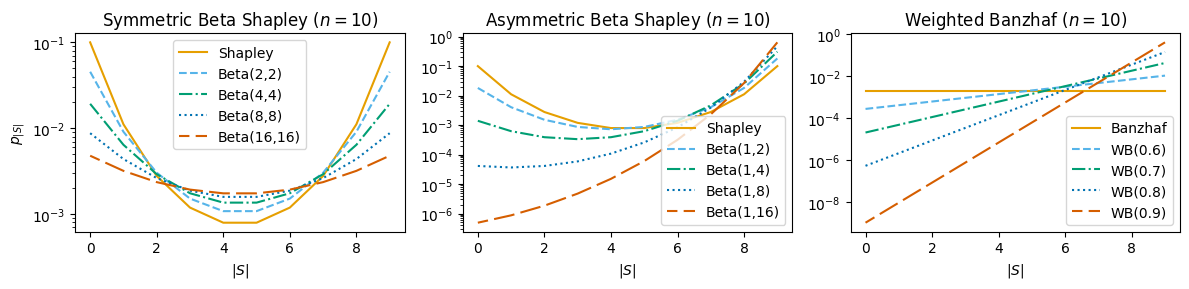

In [ ]:
figsize = (12,3)
#plot_bn(ns=list(range(1,501)), figsize=figsize)
#plot_bn(ns=list(range(1,501, 1)), figsize=figsize, plot_sum=True)

plot_probabilistic_values(n=10, figsize=figsize)
